# 밈타 v2 — "이 밈 지금 써도 돼?" 판단 에이전트
**과제#2(유튜브 댓글 BERTopic 분석)의 확장** · 순천향대학교 AI빅데이터학과 이소미

과제#2는 댓글 6,420건으로 **유행어의 생애 단계**(언제 떴고 지금 어디쯤인가)를 판정했다. 하지만 마케터가 실제로 묻는 건 "그래서 이거 **써도 돼?**"다.
생애 단계만으로는 답할 수 없는 두 가지가 남아 있었다.

1. **사람들이 그 밈에 반발하고 있는가?** → 과제#2는 언급 '양'만 셌고 '감정'은 보지 않았다.
2. **그 밈에 어떤 맥락·리스크가 얽혀 있는가?** → 결과 보고서 인사이트 ②③④에 적었지만 사람이 읽어야만 쓸 수 있었다.

v2는 과제#2 산출물을 **다시 만들지 않고 그대로 입력으로 쓰고**, 그 위에 수업 4·6·7·8장 기법을 하나씩 얹는다.

| 단계 | 과제#2 (v1)에서 가져온 것 | v2에서 새로 한 것 | 수업 |
|---|---|---|---|
| 데이터 | 댓글 6,420건, 전처리 코드, ko-SRoBERTa 임베딩 4,974×768 | 그대로 재사용 (재수집·재임베딩 없음) | – |
| 역풍 감성 | – | 정답셋 300건 직접 레이블링, 분류기 4종 비교 → 밈별 역풍 비율 | **4장** |
| 생애 단계 | BERTopic 38토픽, 유행어 30개 생애 단계 | 생애 단계 × 역풍 비율 2축 지도 | **5장** (재사용) |
| 맥락 지식 | 토픽 레이블·결과 보고서 인사이트 | 맥락 카드 48장 + 하이브리드 검색 | **8장** |
| 판단 | 사람이 표를 읽고 판단 | 도구 3개를 고르는 ReAct 에이전트 | **7장** |
| 설명 | – | 규칙 판정 + 근거 인용 프롬프트 (3가지 프롬프트 비교) | **6장** |

```
 질문 "카페 릴스에 럭키비키 써도 돼?"
       │
 [7장 ReAct 에이전트 · EXAONE-3.5-7.8B]
       ├─ meme_lifecycle ── 과제#2 생애 단계표 (5장 BERTopic 산출물)
       ├─ backlash_scan ─── 4장 역풍 분류기로 라벨링한 언급 댓글
       └─ meme_context ──── 8장 맥락 카드 RAG (BM25 + 임베딩 + RRF)
       │
 [규칙 판정] 🟢 추천 / 🟡 조건부 / 🔴 비추천 / ⚪ 판단 보류
       │
 [6장 근거 생성] 판정은 바꾸지 않고, 근거 번호를 달아 설명만 한다
```

**설계 원칙 (과제#2 인사이트 ⑤에서 이어짐):** 과제#2에서 소형 LLM 토픽 레이블 오답률이 24%였다. 그래서 v2에서도 **판정은 규칙이, 설명은 LLM이** 맡는다. LLM이 판정을 직접 내리면 어떻게 되는지는 6장 실험에서 비교한다.

In [1]:
# ── 0. 환경 설정 ──
# 하는 일: 라이브러리·경로·시드를 준비하고, GPU가 있는지 확인한다.
# 목적  : LLM(EXAONE)은 GPU가 있어야 돈다. GPU가 없으면 4장(d)·7장·6장 LLM 셀은 건너뛰고 나머지만 실행한다.
import os, re, html, json, time, warnings
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"   # 다운로드 진행 막대가 노트북 출력에 쌓이지 않게
os.environ["TQDM_DISABLE"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch
warnings.filterwarnings("ignore")
plt.rcParams["font.family"] = "Malgun Gothic"; plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.max_colwidth", 80); pd.set_option("display.width", 200)

SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
V1 = "../MEMETA_BERTopic/"          # 과제#2 폴더 — 여기 있는 파일을 읽기만 한다
os.makedirs("outputs", exist_ok=True); os.makedirs("figures", exist_ok=True)

USE_LLM = torch.cuda.is_available()
print("GPU:", torch.cuda.get_device_name(0) if USE_LLM else "없음 → LLM 단계 건너뜀")

GPU: 없음 → LLM 단계 건너뜀


## 1. 과제#2 산출물 불러오기 (재사용)
과제#2 노트북의 전처리 코드를 **한 글자도 바꾸지 않고** 다시 돌려 4,974건을 재현한다. 결과가 저장된 임베딩(`embeddings.npy`)과 행 수까지 일치해야 v1의 임베딩·토픽·생애 단계를 v2에서 그대로 쓸 수 있다.

In [2]:
# ── 1-1. [재사용] 원본 댓글 6,420건 + 과제#2 전처리 ──
# 하는 일: 과제#2의 clean() 함수와 필터(길이 8~300자, 중복 제거, 한글 비율 50% 이상)를 그대로 적용한다.
# 목적  : 과제#2 임베딩 파일과 같은 순서·같은 개수의 문서를 얻는다. assert 로 일치를 확인한다.
raw = pd.read_csv(V1 + "youtube_meme_comments_raw.csv")
raw["seg"] = raw["group"].map({"밈원본": "하입", "밈트렌드": "하입", "밈마케팅": "마케팅", "밈역풍": "역풍"})

URL = re.compile(r'https?://\S+|www\.\S+'); TAG = re.compile(r'<[^>]+>')
TS = re.compile(r'\b\d{1,2}:\d{2}(?::\d{2})?\b'); MENTION = re.compile(r'@[\w가-힣._-]+')
HASH = re.compile(r'#(\S+)')
EMOJI = re.compile('[\U0001F000-\U0001FAFF\U00002600-\U000027BF️‍]+')
KEEP = re.compile(r'[^가-힣ㄱ-ㅎㅏ-ㅣa-zA-Z0-9\s.,!?~%]')
REP_JAMO = re.compile(r'([ㄱ-ㅎㅏ-ㅣ])\1{2,}'); REP_CH = re.compile(r'(.)\1{3,}')

def clean(t):
    t = html.unescape(str(t))
    t = URL.sub(' ', t); t = TAG.sub(' ', t); t = MENTION.sub(' ', t); t = TS.sub(' ', t)
    t = HASH.sub(r'\1', t); t = EMOJI.sub(' ', t); t = KEEP.sub(' ', t)
    t = REP_JAMO.sub(r'\1\1', t); t = REP_CH.sub(r'\1\1\1', t)
    return re.sub(r'\s+', ' ', t).strip()

df = raw.copy()
df["clean"] = df.text.map(clean)
df["clen"] = df.clean.str.replace(r'[ㄱ-ㅎㅏ-ㅣ\s.,!?~]', '', regex=True).str.len()
df["hangul_ratio"] = df.clean.map(lambda t: len(re.findall('[가-힣ㄱ-ㅎ]', t)) / max(len(re.sub(r'\s', '', t)), 1))
df = df[(df.clen >= 8) & (df.clen <= 300)].drop_duplicates("clean")
df = df[df.hangul_ratio >= 0.5].reset_index(drop=True)

emb = np.load(V1 + "embeddings.npy")          # 과제#2에서 계산한 ko-SRoBERTa 임베딩 (정규화됨)
assert len(df) == len(emb) == 4974, "과제#2 전처리 결과와 달라졌다"
print(f"원본 {len(raw):,}건 → 분석 {len(df):,}건 / 임베딩 {emb.shape} 재사용")
df.seg.value_counts()

원본 6,420건 → 분석 4,974건 / 임베딩 (4974, 768) 재사용


seg
하입     3413
마케팅    1030
역풍      531
Name: count, dtype: int64

In [3]:
# ── 1-2. [재사용] 과제#2의 유행어 생애 단계표 · 토픽 레이블 ──
# 하는 일: 과제#2가 저장한 CSV 두 개를 읽는다.
# 목적  : 생애 단계표는 7장 에이전트의 meme_lifecycle 도구가 그대로 조회한다. BERTopic을 다시 학습하지 않는다.
life = pd.read_csv(V1 + "meme_word_lifecycle.csv")         # 유행어 30개 × (n, lift 3구간, 중앙 경과일, 단계)
topics = pd.read_csv(V1 + "topic_labels_reviewed.csv")     # 38개 토픽의 최종 레이블·분류
print("유행어", len(life), "개 / 토픽", len(topics), "개")
print(life.단계.value_counts().to_dict())
life.head(6)

유행어 30 개 / 토픽 38 개
{'🔴 지난 유행': 17, '🟡 현재 유행(정점)': 9, '🟢 시작·상승': 2, '⚪ 상시': 2}


,유행어,n,lift_최근,lift_중기,lift_과거,중앙_경과일,단계
0,홍명보,16,8.00,0.00,0.13,30,🟢 시작·상승
1,조교,11,1.55,2.13,0.00,152,🟢 시작·상승
2,케데헌,6,1.42,2.17,0.00,273,🟡 현재 유행(정점)
3,뇌절,20,1.28,1.82,0.30,273,🟡 현재 유행(정점)
4,대나무,12,0.71,2.38,0.00,273,🟡 현재 유행(정점)
5,브레인롯,42,0.20,2.54,0.00,273,🟡 현재 유행(정점)


## 2. [4장] 역풍 감성 분류
**문제:** 과제#2의 생애 단계는 '얼마나 자주 언급되는가'만 본다. 언급이 많아도 그게 조롱·피로·불매라면 브랜드가 쓰면 안 된다.

**레이블 정의 (3종)**
| 레이블 | 기준 | 예 |
|---|---|---|
| 역풍 | 밈 또는 그 밈을 쓴 브랜드·기관·모델을 비판·조롱·불매하거나 밈 피로를 드러냄 | "MZ라는 용어도 멸시적", "요즘은 ㅈㄸ 볼게없음" |
| 호감 | 광고·밈·콘텐츠를 칭찬하거나 재밌어하거나 구매 의향을 보임 | "방금 구매 갈기고 왔긔", "광고 진짜 잘뽑았어" |
| 중립 | 평가가 없는 정보·질문·잡담, 다른 대상에 대한 말 | "풀영상은 어디서 보나요?" |

**정답셋 400건 (`data/gold_backlash.csv`)** — 위 기준으로 직접 레이블링했다.
- **1차 300건:** 세그먼트별 무작위 추출(역풍 110 · 마케팅 110 · 하입 80). 역풍 댓글이 드물어서 역풍·마케팅 영상을 많이 뽑았다.
- **2차 100건:** 1차로 학습한 분류기를 전체에 적용해 보니, "꽁꽁 얼어붙은 한강 위 고양이 묵찌빠 마라탕후루…"처럼 **밈 이름을 나열한 댓글을 역풍으로 오분류**했다. 1차 표본에 이런 댓글이 거의 없었기 때문이다(학습 분포 ≠ 적용 분포). 그래서 유행어를 언급한 댓글을 밈마다 최대 4건씩 100건 더 뽑아 레이블링했다. 밈별 역풍 비율은 바로 이 댓글들로 계산하므로 여기서 맞아야 한다.

**비교한 방법 (4장 순서)**
- (a) 사전학습된 **감성 모델** — NSMC(영화 리뷰)로 학습된 KoELECTRA. 책의 Twitter-RoBERTa 감성 모델에 해당
- (b) **임베딩 제로샷** — 레이블 설명문 임베딩과 댓글 임베딩의 코사인 유사도
- (c) **임베딩 + 로지스틱 회귀** — 과제#2 임베딩을 특징으로, 5-fold 교차검증
- (d) **생성 모델 퓨샷** — EXAONE-3.5-7.8B에 정의와 예시 3개를 주고 한 단어로 답하게 함

핵심 지표는 **역풍 F1**이다. 놓치면(재현율↓) 위험한 밈을 추천하고, 과하게 잡으면(정밀도↓) 쓸 만한 밈을 막는다.

In [4]:
# ── 2-1. 정답셋 불러오기 ──
# 하는 일: 직접 레이블링한 400건을 읽고, 과제#2 문서 번호(doc_id)로 임베딩을 꺼낸다.
# 목적  : 정답셋 텍스트가 재현한 df 와 같은지 확인해 임베딩 정렬이 맞는지 검증한다.
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score, confusion_matrix

gold = pd.read_csv("data/gold_backlash.csv")
assert (df.clean.values[gold.doc_id.values] == gold.clean.values).all()
LABELS = ["역풍", "호감", "중립"]
y = gold.label.values
Xg = emb[gold.doc_id.values]

results = {}
def score(name, pred):
    """역풍 정밀도·재현율·F1 + 3클래스 macro-F1 을 기록한다."""
    pred = np.asarray(pred); b, bp = (y == "역풍"), (pred == "역풍")
    results[name] = {"역풍 정밀도": precision_score(b, bp, zero_division=0), "역풍 재현율": recall_score(b, bp),
                     "역풍 F1": f1_score(b, bp), "macro-F1": f1_score(y, pred, average="macro", labels=LABELS),
                     "정확도": accuracy_score(y, pred)}
    return {k: round(v, 3) for k, v in results[name].items()}

pd.crosstab([gold.세트, gold.seg], gold.label, margins=True, margins_name="합계")

label        역풍   중립   호감   합계
세트      seg                   
1차 세그먼트 마케팅   4   49   57  110
        역풍   51   29   30  110
        하입    5   53   22   80
2차 밈 언급 마케팅   0    0    1    1
        역풍    4    0    0    4
        하입    5   79   11   95
합계           69  210  121  400

In [5]:
# ── 2-2. (a) 사전학습 감성 모델: NSMC 영화 리뷰 감성 ──
# 하는 일: 영화 리뷰 긍·부정으로 학습된 KoELECTRA-small 로 댓글의 부정 확률을 구한다.
# 목적  : "부정 감성 = 역풍"으로 봐도 되는지 확인한다. 이 모델은 중립이 없어서
#         부정 확률 > 0.9 → 역풍, < 0.1 → 호감, 나머지 → 중립으로 나눴다.
from transformers import pipeline
nsmc = pipeline("text-classification", model="daekeun-ml/koelectra-small-v3-nsmc", device=-1)
out = nsmc(gold.clean.str[:300].tolist(), batch_size=32, truncation=True)
neg = np.array([o["score"] if o["label"] == "0" else 1 - o["score"] for o in out])   # label '0' = 부정
pred_a = np.where(neg > 0.9, "역풍", np.where(neg < 0.1, "호감", "중립"))
print(score("(a) 감성 모델 (NSMC)", pred_a))

# 부정 감성인데 역풍이 아닌 예 — 감성과 역풍이 다른 개념이라는 증거
miss = gold[(pred_a == "역풍") & (y != "역풍")]
miss[["seg", "label", "clean"]].head(6)

{'역풍 정밀도': 0.252, '역풍 재현율': 0.594, '역풍 F1': 0.353, 'macro-F1': 0.401, '정확도': 0.403}


,seg,label,clean
5,역풍,호감,직원분이 너무 불쌍하다...하나 사드려야겠다
6,역풍,중립,담당자 분도 페잌 택시를 아는거였어..
18,역풍,중립,헐 벗방하는 여자였구나 남자친구도 길거리 비제이던데 헐..
25,역풍,중립,후라이드 부부에게서 양념이 태어난거면 불륜 맞네
28,역풍,중립,불륜천국세상인데 뭐가 문제여?
35,역풍,호감,광고주까지 조져버리는 핫소스 클라스


In [6]:
# ── 2-3. (b) 임베딩 제로샷 분류 ──
# 하는 일: 레이블마다 설명문을 하나씩 쓰고, 과제#2와 같은 ko-SRoBERTa 로 임베딩해 가장 가까운 레이블을 고른다.
# 목적  : 학습 데이터 없이 어디까지 되는지 본다. 이 모델(st)은 8장 RAG 검색에도 그대로 쓴다.
from sentence_transformers import SentenceTransformer
st = SentenceTransformer("jhgan/ko-sroberta-multitask", device="cpu")   # 과제#2 임베딩 모델 (VRAM은 LLM에 양보)

DESC = {"역풍": "광고나 브랜드, 밈을 쓴 회사를 비판하고 조롱하며 불매하겠다는 부정적인 반응",
        "호감": "광고나 밈이 재밌고 좋다며 칭찬하고 제품을 사고 싶다는 긍정적인 반응",
        "중립": "광고나 밈에 대한 평가 없이 정보를 말하거나 질문하는 잡담"}
label_emb = st.encode(list(DESC.values()), normalize_embeddings=True)
pred_b = np.array(list(DESC))[(Xg @ label_emb.T).argmax(1)]
print(score("(b) 임베딩 제로샷", pred_b))

{'역풍 정밀도': 0.368, '역풍 재현율': 0.406, '역풍 F1': 0.386, 'macro-F1': 0.471, '정확도': 0.495}


In [7]:
# ── 2-4. (c) 임베딩 + 로지스틱 회귀 (5-fold 교차검증) ──
# 하는 일: 과제#2 임베딩(768차원)을 특징으로 로지스틱 회귀를 학습한다. 400건뿐이라 5-fold 교차검증 예측으로 평가한다.
# 목적  : 역풍이 69건(17%)뿐이라 class_weight='balanced' 로 소수 클래스에 가중치를 준다.
#         가중치가 없으면 다수 클래스(중립)만 맞히는 쪽으로 쏠려 역풍 재현율이 크게 떨어진다. C 는 기본값 1 유지.
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict

cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
pred_c_plain = cross_val_predict(LogisticRegression(max_iter=2000), Xg, y, cv=cv)
print("가중치 없음 :", score("(c-0) 임베딩+LR (가중치 없음)", pred_c_plain))
pred_c = cross_val_predict(LogisticRegression(max_iter=2000, class_weight="balanced"), Xg, y, cv=cv)
print("balanced    :", score("(c) 임베딩+LR (balanced)", pred_c))
del results["(c-0) 임베딩+LR (가중치 없음)"]

가중치 없음 : {'역풍 정밀도': 0.71, '역풍 재현율': 0.319, '역풍 F1': 0.44, 'macro-F1': 0.668, '정확도': 0.745}
balanced    : {'역풍 정밀도': 0.459, '역풍 재현율': 0.652, '역풍 F1': 0.539, 'macro-F1': 0.69, '정확도': 0.713}


In [8]:
# ── 2-4b. 학습 분포 ≠ 적용 분포: 1차 300건만으로 학습하면? ──
# 하는 일: 1차 300건(세그먼트 표본)으로만 학습한 분류기를 2차 100건(밈 언급 댓글)에 적용한다.
# 목적  : 2차 레이블링이 왜 필요했는지 숫자로 보인다. 밈 나열 댓글을 역풍으로 몇 건 잘못 잡는지 센다.
s1, s2 = (gold.세트 == "1차 세그먼트").values, (gold.세트 == "2차 밈 언급").values
lr1 = LogisticRegression(max_iter=2000, class_weight="balanced").fit(Xg[s1], y[s1])
p2 = lr1.predict(Xg[s2])
print(f"2차 100건(밈 언급) 정답 역풍 {(y[s2] == '역풍').sum()}건 / 1차로만 학습한 분류기의 역풍 예측 {(p2 == '역풍').sum()}건"
      f" (그중 실제 역풍 {((p2 == '역풍') & (y[s2] == '역풍')).sum()}건)")
print(f"→ 2차 세트 정확도: 1차만 학습 {accuracy_score(y[s2], p2):.2f} / 400건 교차검증 {accuracy_score(y[s2], pred_c[s2]):.2f}")
wrong = gold[s2].assign(예측=p2)[lambda d: (d.예측 == "역풍") & (d.label != "역풍")]
wrong[["label", "예측", "clean"]].head(5)

2차 100건(밈 언급) 정답 역풍 9건 / 1차로만 학습한 분류기의 역풍 예측 19건 (그중 실제 역풍 5건)
→ 2차 세트 정확도: 1차만 학습 0.66 / 400건 교차검증 0.87


,label,예측,clean
303,중립,역풍,"홍명보 월드컵 참사, 투표지 부족, ufc 백악관 무조건 나올꺼 같으면 개추"
305,중립,역풍,무다무다로만 조교해주세요
323,중립,역풍,옛날에도 별 의미 없이 그냥 밈이니까 사용되는 밈은 많았음 그런데 요즘은 그런 것들이 브레인롯이라는 키워드 아래에 묶여서 생산되다보니 다...
328,중립,역풍,햄부기? 그건 왜 없지
357,중립,역풍,꽁꽁 얼어붙은 한강위로 고양이가 걸어다닙니다 ㅋㅋ


### (d) 생성 모델 퓨샷 분류 — EXAONE-3.5-7.8B
7장 에이전트와 6장 근거 생성에서도 같은 모델을 쓰므로 여기서 한 번만 올린다.
- **4bit(nf4) + `dtype=bfloat16`**: config 에 float32 가 적혀 있어 dtype 을 안 주면 8GB 를 넘겨 CPU 로 밀려난다 (프롬프트엔지니어링 과제에서 확인).
- **transformers 5 호환 패치**: EXAONE 원격 코드가 `create_causal_mask(input_embeds=…)` 옛 인자를 써서 `generate()` 가 `TypeError` 로 멈춘다. 졸업요건 RAG 챗봇에서 만든 패치를 그대로 가져왔다.
- 퓨샷 예시 3개는 **정답셋에 없는 문장을 직접 작성**했다. 정답셋 문장을 예시로 넣으면 평가가 부풀려진다.

In [9]:
# ── 2-5. EXAONE-3.5-7.8B-Instruct 4bit 로드 ──
# 하는 일: EXAONE 을 GPU 에 4bit 로 올리고, 대화 템플릿 → 생성 → 디코딩을 exaone_chat() 하나로 묶는다.
# 목적  : 4장(d)·7장·6장이 모두 이 함수 하나를 쓴다. stop 문자열(ReAct 의 "Observation")에서 생성을 멈출 수 있게 한다.
def patch_exaone_for_transformers5():
    """EXAONE-3.5 원격 코드 × transformers 5.x 호환 패치 (졸업요건_RAG챗봇/rag/generator.py 와 동일).
    transformers 5 에서 create_causal_mask() 인자가 input_embeds → inputs_embeds 로 바뀌고 cache_position 이 사라졌다.
    옛 인자 이름을 새 이름으로 바꿔 넘기는 래퍼를 끼우고, 이미 import 된 원격 모듈에도 다시 꽂는다."""
    import inspect, sys
    import transformers.masking_utils as mu
    orig = getattr(mu, "_orig_create_causal_mask", mu.create_causal_mask)
    allowed = set(inspect.signature(orig).parameters)
    if "input_embeds" in allowed:            # transformers 4.x 면 필요 없음
        return
    def compat(*args, **kw):
        if "input_embeds" in kw: kw["inputs_embeds"] = kw.pop("input_embeds")
        return orig(*args, **{k: v for k, v in kw.items() if k in allowed})
    mu._orig_create_causal_mask = orig; mu.create_causal_mask = compat
    for name, m in list(sys.modules.items()):
        if name.startswith("transformers_modules") and hasattr(m, "create_causal_mask"):
            m.create_causal_mask = compat

if USE_LLM:
    from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig, GenerationConfig
    LLM_ID = "LGAI-EXAONE/EXAONE-3.5-7.8B-Instruct"
    t0 = time.time()
    patch_exaone_for_transformers5()
    tok = AutoTokenizer.from_pretrained(LLM_ID, trust_remote_code=True)
    model = AutoModelForCausalLM.from_pretrained(
        LLM_ID, trust_remote_code=True, device_map="cuda", dtype=torch.bfloat16,
        quantization_config=BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                               bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=torch.bfloat16))
    patch_exaone_for_transformers5()          # from_pretrained 중에 새로 import 된 원격 모듈에도 적용
    model.eval()
    # 생성 설정: 모델 기본값에 덮어쓰기 (샘플링 관련 키를 기본값으로 둬야 경고가 안 뜬다)
    BASE_GEN = {**model.generation_config.to_dict(), "do_sample": False, "temperature": 1.0, "top_p": 1.0, "top_k": 50,
                "repetition_penalty": 1.05, "pad_token_id": tok.pad_token_id or tok.eos_token_id}
    print(f"EXAONE 로드 {time.time() - t0:.0f}초 / VRAM {torch.cuda.memory_allocated() / 1024**3:.1f}GB")

def exaone_chat(messages, max_new_tokens=512, stop=None):
    """messages(대화 목록) → EXAONE 응답 문자열. stop 문자열이 나오면 거기서 자른다."""
    prompt = tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    ids = tok(prompt, return_tensors="pt").to(model.device)
    gen = GenerationConfig.from_dict({**BASE_GEN, "max_new_tokens": max_new_tokens, "stop_strings": stop or None})
    with torch.no_grad():
        out = model.generate(**ids, generation_config=gen, tokenizer=tok)
    text = tok.decode(out[0][ids["input_ids"].shape[1]:], skip_special_tokens=True, clean_up_tokenization_spaces=False)
    for s in stop or []:
        text = text.split(s)[0]
    return text.strip()

In [10]:
# ── 2-6. (d) EXAONE 퓨샷 분류 ──
# 하는 일: 레이블 정의 + 직접 쓴 예시 3개 + 댓글을 주고 '역풍/호감/중립' 한 단어로 답하게 한다. 16개씩 묶어 배치 생성한다.
# 목적  : 생성 모델이 '광고를 향한 비판'과 '그냥 부정적인 말'을 구분하는지 본다.
CLS_SYSTEM = "너는 유튜브 댓글이 밈·광고·브랜드에 보이는 반응을 분류하는 평가자다. 반드시 한 단어로만 답한다."
CLS_USER = """아래 기준으로 댓글을 분류하라.
- 역풍: 밈이나 그 밈을 쓴 브랜드·기관·모델을 비판, 조롱, 불매하거나 '요즘 밈 재미없다' 같은 밈 피로를 드러냄
- 호감: 광고·밈·콘텐츠를 칭찬하거나 재밌어하거나 사고 싶어 함
- 중립: 평가 없는 정보·질문·잡담, 또는 광고·밈이 아닌 다른 대상에 대한 말

예시)
댓글: 이런 걸 광고라고 내보낸 회사도 대단하다 다신 안 산다 → 역풍
댓글: 담당자분 센스 미쳤다 ㅋㅋ 바로 주문함 → 호감
댓글: 이 노래 원곡 제목 아시는 분? → 중립

댓글: {text}
답:"""

def exaone_classify(texts, bs=16):
    tok.padding_side = "left"                                   # 배치 생성은 왼쪽 패딩이어야 끝이 맞는다
    gen = GenerationConfig.from_dict({**BASE_GEN, "max_new_tokens": 4})
    preds = []
    for i in range(0, len(texts), bs):
        prompts = [tok.apply_chat_template([{"role": "system", "content": CLS_SYSTEM},
                                            {"role": "user", "content": CLS_USER.format(text=t[:300])}],
                                           tokenize=False, add_generation_prompt=True) for t in texts[i:i + bs]]
        enc = tok(prompts, return_tensors="pt", padding=True).to(model.device)
        with torch.no_grad():
            out = model.generate(**enc, generation_config=gen)
        for o in tok.batch_decode(out[:, enc["input_ids"].shape[1]:], skip_special_tokens=True):
            preds.append(next((l for l in LABELS if l in o), "중립"))   # 형식을 어기면 중립 처리
    tok.padding_side = "right"
    return np.array(preds)

if USE_LLM:
    t0 = time.time()
    pred_d = exaone_classify(gold.clean.tolist())
    print(f"{time.time() - t0:.0f}초 /", score("(d) EXAONE 퓨샷", pred_d))

,역풍 정밀도,역풍 재현율,역풍 F1,macro-F1,정확도
(a) 감성 모델 (NSMC),0.252,0.594,0.353,0.401,0.402
(b) 임베딩 제로샷,0.368,0.406,0.386,0.471,0.495
(c) 임베딩+LR (balanced),0.459,0.652,0.539,0.690,0.712


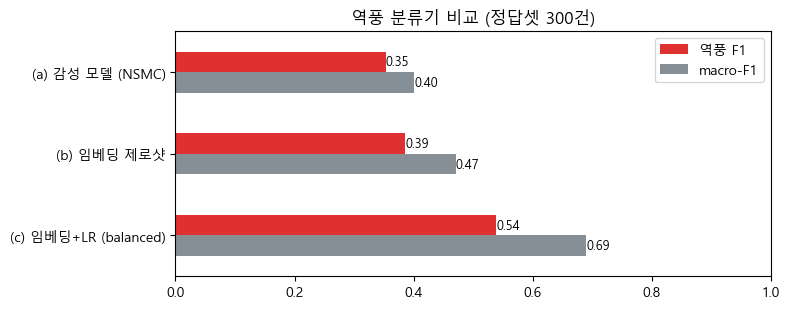

선택: (c) 임베딩+LR (balanced)


,예측 역풍,예측 호감,예측 중립
정답 역풍,45,6,18
정답 호감,7,100,14
정답 중립,46,24,140


In [11]:
# ── 2-7. 방법 비교 ──
# 하는 일: 4가지 방법의 지표를 한 표·한 그림으로 모으고, 가장 좋은 방법의 혼동 행렬을 본다.
# 목적  : 역풍 F1 이 가장 높은 방법을 고른다. 그 방법으로 밈별 역풍 비율을 계산한다.
comp = pd.DataFrame(results).T.round(3)
comp.to_csv("outputs/ch4_classifier_comparison.csv", encoding="utf-8-sig")
display(comp)

ax = comp[["역풍 F1", "macro-F1"]].plot.barh(figsize=(8, 3.2), color=["#E03131", "#868E96"])
ax.set_xlim(0, 1); ax.invert_yaxis(); ax.set_title("역풍 분류기 비교 (정답셋 300건)")
for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=9)
plt.tight_layout(); plt.savefig("figures/01_classifier_comparison.png", dpi=150); plt.show()

BEST = comp["역풍 F1"].idxmax()
best_pred = {"(a) 감성 모델 (NSMC)": pred_a, "(b) 임베딩 제로샷": pred_b, "(c) 임베딩+LR (balanced)": pred_c}
if USE_LLM: best_pred["(d) EXAONE 퓨샷"] = pred_d
print("선택:", BEST)
pd.DataFrame(confusion_matrix(y, best_pred[BEST], labels=LABELS),
             index=[f"정답 {l}" for l in LABELS], columns=[f"예측 {l}" for l in LABELS])

In [12]:
# ── 2-8. 전체 댓글에 적용 → 밈별 역풍 비율 ──
# 하는 일: (1) 로지스틱 회귀를 정답셋 300건 전체로 다시 학습해 4,974건 모두에 붙인다 (빠르고, 세그먼트 검증용).
#          (2) 선택된 방법이 EXAONE 이면, 유행어를 언급한 댓글만 EXAONE 으로 다시 분류한다 (밈별 비율용).
#          (3) 유행어 30개마다 언급 댓글의 역풍·호감·중립 수를 센다.
# 목적  : 과제#2 생애 단계표에 '역풍 비율' 열을 붙여 7장 에이전트의 backlash_scan 도구가 조회하게 한다.
lr = LogisticRegression(max_iter=2000, class_weight="balanced").fit(Xg, y)
df["pred_lr"] = lr.predict(emb)

MEME_KEYS = life.유행어.tolist()
mention = {k: df.clean.str.contains(k, regex=False).values for k in MEME_KEYS}   # 과제#2와 같은 부분 문자열 매칭
any_mention = np.logical_or.reduce(list(mention.values()))
df["backlash"] = df.pred_lr
if BEST.startswith("(d)"):
    idx = np.where(any_mention)[0]
    t0 = time.time()
    df.loc[idx, "backlash"] = exaone_classify(df.clean.values[idx].tolist())
    print(f"유행어 언급 댓글 {len(idx)}건 EXAONE 재분류 {time.time() - t0:.0f}초")
df.loc[gold.doc_id.values, "backlash"] = y           # 사람이 레이블한 300건은 정답을 그대로 쓴다

# 검증: 역풍 영상 댓글에서 역풍 비율이 가장 높아야 한다
seg_check = pd.crosstab(df.seg, df.pred_lr, normalize="index").round(3)[LABELS]
display(seg_check)

rows = []
for k in MEME_KEYS:
    vc = df.loc[mention[k], "backlash"].value_counts()
    n = int(mention[k].sum())
    rows.append({"유행어": k, "언급": n, "역풍": vc.get("역풍", 0), "호감": vc.get("호감", 0), "중립": vc.get("중립", 0),
                 "역풍비율": round(vc.get("역풍", 0) / n, 3)})
risk = life.merge(pd.DataFrame(rows), on="유행어")
risk.to_csv("outputs/meme_risk_table.csv", index=False, encoding="utf-8-sig")
df[["comment_id", "seg", "clean", "pred_lr", "backlash"]].to_csv("outputs/comment_backlash_pred.csv", index=False, encoding="utf-8-sig")
HYPE_BASE = (df.loc[df.seg == "하입", "backlash"] == "역풍").mean()
print(f"하입 영상 댓글 전체 역풍 비율(기준선): {HYPE_BASE:.1%}")
risk.sort_values("역풍비율", ascending=False)[["유행어", "단계", "언급", "역풍", "호감", "중립", "역풍비율"]].head(12)

pred_lr,역풍,호감,중립
seg,,,
마케팅,0.179,0.522,0.299
역풍,0.533,0.269,0.198
하입,0.137,0.232,0.631


하입 영상 댓글 전체 역풍 비율(기준선): 13.4%


,유행어,단계,언급,역풍,호감,중립,역풍비율
10,물정,🟡 현재 유행(정점),19,19,0,0,1.000
3,뇌절,🟡 현재 유행(정점),20,8,3,9,0.400
5,브레인롯,🟡 현재 유행(정점),42,12,4,26,0.286
22,레퀴엠,🔴 지난 유행,8,2,0,6,0.250
28,폼,⚪ 상시,18,4,6,8,0.222
1,조교,🟢 시작·상승,11,2,0,9,0.182
8,얼음,🟡 현재 유행(정점),14,2,3,9,0.143
11,킹받,🔴 지난 유행,14,2,9,3,0.143
20,아파트,🔴 지난 유행,26,3,1,22,0.115
13,계엄,🔴 지난 유행,61,6,9,46,0.098


## 3. [5장 확장] 생애 단계 × 역풍 — 두 축으로 보기
과제#2의 생애 단계(색)별로 유행어를 묶고, 4장에서 구한 역풍 비율(가로축)을 찍었다. 같은 '현재 유행'이라도 경고선 오른쪽에 있으면 피로·조롱 반응이 큰 밈이다.

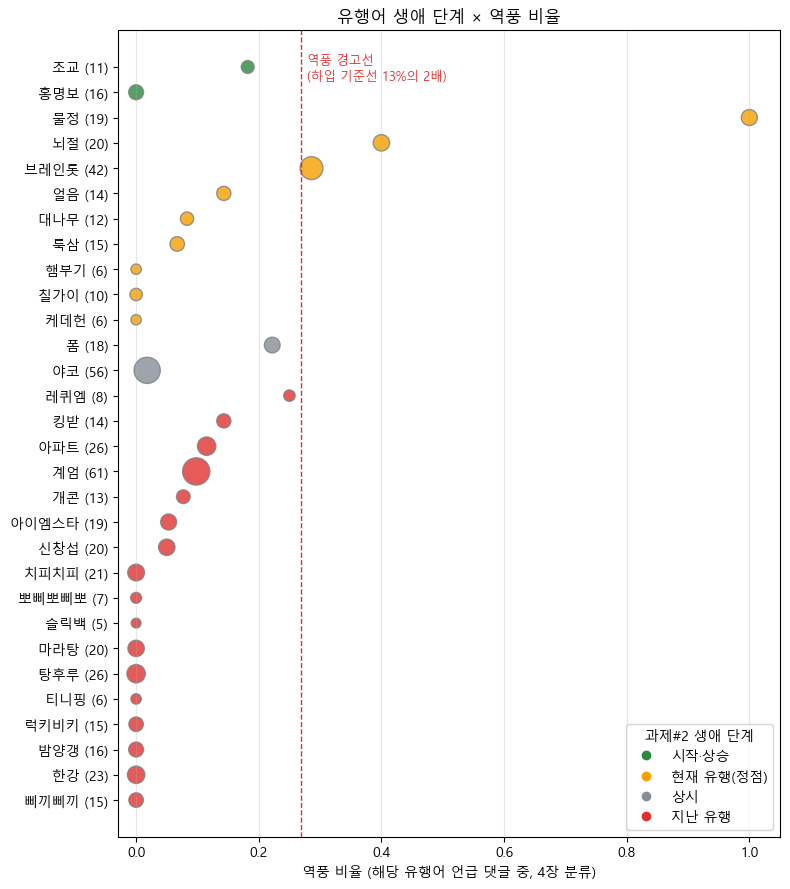

In [13]:
# ── 3-1. 생애 단계 × 역풍 비율 ──
# 하는 일: 세로축 = 유행어(생애 단계별로 묶음, 괄호는 언급 수), 가로축 = 역풍 비율, 점 색 = 과제#2 생애 단계, 점 크기 = 언급 수.
# 목적  : '타이밍'과 '반응'을 한 장에서 보이게 해, 에이전트가 왜 두 도구를 모두 봐야 하는지 보여 준다.
from matplotlib.lines import Line2D
STAGES = ["🔴 지난 유행", "⚪ 상시", "🟡 현재 유행(정점)", "🟢 시작·상승"]            # 아래 → 위
STAGE_COLOR = dict(zip(STAGES, ["#E03131", "#868E96", "#F59F00", "#2B8A3E"]))
d = risk.assign(o=risk.단계.map(STAGES.index)).sort_values(["o", "역풍비율"]).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8, 9))
ax.scatter(d.역풍비율, d.index, s=d.n * 6 + 20, c=d.단계.map(STAGE_COLOR), alpha=0.8, edgecolors="gray")
ax.set_yticks(d.index, [f"{r.유행어} ({r.n})" for r in d.itertuples()])
ax.axvline(2 * HYPE_BASE, ls="--", c="#E03131", lw=1)
ax.text(2 * HYPE_BASE + 0.01, len(d) - 0.5, f"역풍 경고선\n(하입 기준선 {HYPE_BASE:.0%}의 2배)", color="#E03131", fontsize=9, va="top")
ax.legend(handles=[Line2D([], [], marker="o", ls="", color=STAGE_COLOR[s], label=s[2:]) for s in STAGES[::-1]],
          loc="lower right", title="과제#2 생애 단계")
ax.set(xlim=(-0.03, 1.05), xlabel="역풍 비율 (해당 유행어 언급 댓글 중, 4장 분류)",
       title="유행어 생애 단계 × 역풍 비율")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout(); plt.savefig("figures/02_lifecycle_x_backlash.png", dpi=150); plt.show()

## 4. [8장] 밈 맥락 RAG
생애 단계·역풍 비율은 **숫자**라서 도구가 표에서 바로 읽는다. 하지만 "이 밈은 실존 인물 조롱이다", "비슷한 광고가 불매를 맞았다" 같은 **맥락**은 표에 없다. 이걸 카드로 써서 검색한다.

**지식베이스 `data/meme_cards.md` — 48장**
| 종류 | 수 | 내용 | 출처 |
|---|---|---|---|
| 밈(M) | 30 | 과제#2 유행어 30개의 기원·의미·리스크·위험도 | 과제#2 댓글·토픽 + 일반 지식(확인 필요 표시) |
| 사례(C) | 10 | 수집한 마케팅·역풍 영상의 브랜드 사례와 교훈 | 과제#2 마케팅·역풍 세그먼트 댓글 |
| 가이드(G) | 8 | 과제#2 결과 보고서 인사이트 ①~④를 실행 규칙으로 | 과제#2 결과 보고서 |

**검색기:** 졸업요건 RAG 챗봇의 하이브리드 검색기 구조를 가져왔다. 임베딩 모델만 과제#2와 같은 ko-SRoBERTa로 바꿨다.
- 밀집 검색(ko-SRoBERTa 코사인): "야구 치어리더 춤" → 삐끼삐끼처럼 단어가 달라도 찾는다
- BM25(한글 2-gram): "케데헌", "625" 같은 고유명사·숫자에 강하다. 형태소 분석기 없이 조사 문제를 피한다
- RRF: 두 순위를 1/(60+순위)로 더한다. 점수 척도가 달라도 정규화 없이 합칠 수 있다

In [14]:
# ── 4-1. 맥락 카드 불러오기 ──
# 하는 일: '## ID 이름' 단위로 카드를 자르고, '- 항목: 값' 줄을 열로 만든다.
# 목적  : 카드의 '데이터 키'·'별칭'·'위험도'는 7장 도구와 판정 규칙이 쓰고, 카드 전체 텍스트는 검색 대상이 된다.
def load_cards(path):
    cards = []
    for block in open(path, encoding="utf-8").read().split("\n## ")[1:]:
        head, *lines = block.strip().split("\n")
        cid, name = head.split(" ", 1)
        fields = {m.group(1): m.group(2).strip() for l in lines if (m := re.match(r"- ([^:]+): (.*)", l))}
        cards.append({"id": cid, "name": name, "text": f"[{cid}] {name}\n" + "\n".join(lines), **fields})
    return pd.DataFrame(cards).set_index("id", drop=False)

cards = load_cards("data/meme_cards.md")
assert set(cards.loc[cards.종류 == "밈", "데이터 키"]) == set(MEME_KEYS), "밈 카드와 생애 단계표의 유행어가 다르다"
print(cards.종류.value_counts().to_dict(), "/ 평균 길이", int(cards.text.str.len().mean()), "자")
cards[["name", "종류", "위험도", "별칭"]].head(8)

{'밈': 30, '사례': 10, '가이드': 8} / 평균 길이 265 자


,name,종류,위험도,별칭
id,,,,
M01,밤양갱,밈,낮음,"밤양갱, 달디단 밤양갱, 비비 밤양갱"
M02,럭키비키,밈,중간,"럭키비키, 원영적 사고, 럭키비키잖아, 완전 럭키비키"
M03,티니핑,밈,중간,"티니핑, 하츄핑, 캐치 티니핑"
M04,삐끼삐끼,밈,중간,"삐끼삐끼, 삐끼삐끼 춤, 기아 치어리더 춤"
M05,탕후루,밈,낮음,"탕후루, 탕후루 챌린지"
M06,마라탕후루,밈,낮음,"마라탕후루, 마라탕, 마라탕 챌린지"
M07,아파트,밈,중간,"아파트, APT, 아파트 아파트, 로제 아파트"
M08,꽁꽁 얼어붙은 한강,밈,낮음,"꽁꽁 얼어붙은 한강, 한강 고양이, 얼어붙은 한강 위로 고양이가"


In [15]:
# ── 4-2. 하이브리드 검색기 (밀집 + BM25 → RRF) ──
# 하는 일: 카드 48장을 ko-SRoBERTa 로 임베딩해 FAISS 내적 인덱스에 넣고, 같은 카드로 BM25 색인을 만든다.
# 목적  : search() 는 두 검색의 상위 10개를 RRF 로 합쳐 top_k 장을 돌려준다. mode 로 한쪽만 쓸 수도 있다 (평가용).
import faiss
from rank_bm25 import BM25Okapi

def ko_bigram(text):
    """한글은 2글자씩, 영문·숫자는 단어 그대로. ('케데헌이' → 케데, 데헌, 헌이)"""
    toks = []
    for w in re.findall(r"[0-9a-z]+|[가-힣]+", text.lower()):
        toks += [w] if (re.fullmatch(r"[0-9a-z]+", w) or len(w) == 1) else [w[i:i + 2] for i in range(len(w) - 1)]
    return toks

class HybridRetriever:
    def __init__(self, cards, encoder, cand_k=10, rrf_k=60):
        self.cards, self.enc, self.cand_k, self.rrf_k = cards.reset_index(drop=True), encoder, cand_k, rrf_k
        vec = encoder.encode(self.cards.text.tolist(), normalize_embeddings=True).astype("float32")
        self.index = faiss.IndexFlatIP(vec.shape[1]); self.index.add(vec)
        self.bm25 = BM25Okapi([ko_bigram(t) for t in self.cards.text])

    def dense(self, q):
        _, ids = self.index.search(self.enc.encode([q], normalize_embeddings=True).astype("float32"), self.cand_k)
        return list(ids[0])

    def sparse(self, q):
        return list(np.argsort(-self.bm25.get_scores(ko_bigram(q)))[:self.cand_k])

    def search(self, q, top_k=3, mode="hybrid"):
        ranks = {"dense": [self.dense(q)], "bm25": [self.sparse(q)], "hybrid": [self.dense(q), self.sparse(q)]}[mode]
        fused = {}
        for r in ranks:
            for rank, i in enumerate(r):
                fused[i] = fused.get(i, 0) + 1 / (self.rrf_k + rank + 1)
        return [self.cards.id[i] for i in sorted(fused, key=fused.get, reverse=True)[:top_k]]

retriever = HybridRetriever(cards, st)
retriever.search("야구 치어리더 춤 밈")

['M04', 'M11', 'M19']

In [16]:
# ── 4-3. 검색 평가: BM25 vs 밀집 vs 하이브리드 ──
# 하는 일: 질문 26개에 정답 카드(1~2장)를 직접 정하고 Hit@1, Hit@3, MRR 을 잰다.
#          질문 절반은 카드 별칭을 그대로 쓰고(어휘 일치), 절반은 다른 말로 바꿨다(의미 일치).
# 목적  : 두 검색을 합치는 게 실제로 나은지 확인한다.
RAG_EVAL = [
    ("꽁꽁 얼어붙은 한강 고양이 밈 써도 돼?", ["M08"]), ("장원영 초긍정 말투로 광고하고 싶어", ["M02", "C01"]),
    ("이탈리아 AI 캐릭터 밈", ["M17"]), ("느긋한 강아지 캐릭터 그림 밈", ["M18"]),
    ("로제 노래 밈으로 챌린지", ["M07"]), ("야구 치어리더 응원 춤", ["M04"]),
    ("축구 대표팀 감독 밈 써도 될까", ["M28"]), ("정치 사건 드립을 광고에", ["G04", "M29"]),
    ("인플루언서를 광고 모델로 쓸 때 주의할 점", ["G03", "C05"]), ("논란 나면 사과문 어떻게 써야 해", ["G03", "C05"]),
    ("공무원들이 춤추는 지역 축제 홍보", ["C02"]), ("AI로 만든 광고 영상 괜찮을까", ["C07", "C03"]),
    ("MZ세대 겨냥 유머 광고", ["C08", "G07"]), ("밈 유행은 보통 얼마나 가?", ["G01"]),
    ("경쟁사가 이미 쓴 밈인데 따라 해도 돼?", ["G02", "C10"]), ("캐릭터 이미지 저작권 괜찮나", ["G06"]),
    ("같은 드립을 계속 반복하면", ["M23", "G08"]), ("요즘 밈 재미없다는 반응이 많던데", ["G08"]),
    ("넷플릭스 애니메이션 노래 밈", ["M20"]), ("어린이 애니 캐릭터 밈", ["M03"]),
    ("충전기 브랜드가 스스로 망가지는 광고", ["C04"]), ("6.25 말장난 광고 문구", ["C06"]),
    ("밈 광고 잘 만드는 방법", ["G05"]), ("효과음 하나로 노래 만드는 편집 놀이", ["M27"]),
    ("닭가슴살 광고 반응", ["C03"]), ("기업이 쓰면 끝물이라는 말", ["C10"]),
]
def rag_eval(mode):
    h1 = h3 = mrr = 0
    for q, gold_ids in RAG_EVAL:
        got = retriever.search(q, top_k=10, mode=mode)
        r = next((i + 1 for i, c in enumerate(got) if c in gold_ids), None)
        h1 += r == 1; h3 += (r or 99) <= 3; mrr += 1 / r if r else 0
    n = len(RAG_EVAL)
    return {"Hit@1": round(h1 / n, 3), "Hit@3": round(h3 / n, 3), "MRR": round(mrr / n, 3)}

rag = pd.DataFrame({m: rag_eval(m) for m in ["bm25", "dense", "hybrid"]}).T
rag.to_csv("outputs/ch8_retrieval_eval.csv", encoding="utf-8-sig")
rag

,Hit@1,Hit@3,MRR
bm25,0.846,0.923,0.892
dense,0.731,0.962,0.846
hybrid,0.808,1.000,0.897


In [17]:
# ── 4-4. 검색이 틀린 질문 살펴보기 ──
# 하는 일: 하이브리드 검색 top-3 에 정답이 없는 질문과, 그때 BM25·밀집 검색이 각각 무엇을 골랐는지 출력한다.
# 목적  : 실패 유형을 보고서에 적기 위해.
for q, g in RAG_EVAL:
    if not set(retriever.search(q, 3)) & set(g):
        print(f"[정답 {g}] {q}\n   hybrid={retriever.search(q, 3)} bm25={retriever.search(q, 3, 'bm25')} dense={retriever.search(q, 3, 'dense')}")

## 5. [7장] LangChain ReAct 에이전트
에이전트는 질문에서 밈 이름과 용도를 읽어 내고, 도구 3개를 골라 부른다.

| 도구 | 하는 일 | 데이터 |
|---|---|---|
| `meme_lifecycle` | 생애 단계, lift, 언급 수 | 과제#2 `meme_word_lifecycle.csv` |
| `backlash_scan` | 언급 댓글의 역풍·호감·중립 수와 역풍 댓글 예시 | 4장 분류 결과 |
| `meme_context` | 맥락 카드 검색 | 8장 하이브리드 검색 |

**판정 규칙** (위에서부터 먼저 걸리는 것)
1. 데이터에 없는 밈 → ⚪ 판단 보류
2. 카드 위험도 '높음'(정치·사건·실존 인물 조롱·타사 논란) → 🔴 비추천
3. 생애 단계 '지난 유행' → 🔴 비추천 (뒷북)
4. 위험도 '중간'(권리·맥락 확인 필요) 또는 역풍 비율이 기준선의 2배 이상(언급 10건 이상) → 🟡 조건부
5. 나머지 → 🟢 추천

7.8B 모델이 도구 선택을 매번 다르게 하면 같은 질문에 다른 답이 나온다. 그래서 프롬프트에서 "세 도구를 한 번씩 부른다"는 순서를 정해 주고, 에이전트는 **밈 이름 인식·도구 입력 작성·검색어 작성**을 맡는다. 에이전트가 빠뜨린 도구는 파이프라인이 대신 불러 채우고, 그 횟수를 따로 센다.

In [18]:
# ── 5-1. 도구 3개 ──
# 하는 일: 밈 이름(별칭 포함)을 생애 단계표의 유행어로 바꾸는 resolve() 와, 도구 함수 3개를 만든다.
# 목적  : 도구 결과는 6장 근거 생성에 그대로 들어가므로 출처·숫자를 한 줄로 분명히 적는다.
from langchain_core.tools import Tool

# 별칭 + 데이터 키(2글자 이상만 — '폼'은 '플랫폼'에도 걸리므로 제외)
ALIAS = sorted({(a.strip().replace(" ", "").lower(), r["데이터 키"], r.id)
                for _, r in cards[cards.종류 == "밈"].iterrows()
                for a in r.별칭.split(",") + ([r["데이터 키"]] if len(r["데이터 키"]) > 1 else [])}, key=lambda x: -len(x[0]))

def resolve(text):
    """문장 속 밈 별칭(공백 무시) 중 가장 긴 것을 찾아 (데이터 키, 카드 ID)를 돌려준다. 없으면 (None, None)."""
    t = str(text).replace(" ", "").lower()
    return next(((key, cid) for a, key, cid in ALIAS if a in t), (None, None))

life_i, risk_i = life.set_index("유행어"), risk.set_index("유행어")

def meme_lifecycle(q):
    key, _ = resolve(q)
    if key is None:
        return f"'{q}'는 과제#2 데이터(유행어 30개)에 없어 생애 단계를 알 수 없다."
    r = life_i.loc[key]
    return (f"{key}: {r.단계} | 언급 {r.n}건 | lift 최근 {r.lift_최근:.2f} / 중기 {r.lift_중기:.2f} / 과거 {r.lift_과거:.2f}"
            f" | 언급 댓글 작성 시점 중앙값 {r.중앙_경과일}일 전")

def backlash_scan(q):
    key, _ = resolve(q)
    if key is None:
        return f"'{q}'를 언급한 댓글이 과제#2 데이터에 없다."
    r = risk_i.loc[key]
    ex = df.loc[mention[key] & (df.backlash == "역풍"), "clean"].str[:60].head(2).tolist()
    return (f"{key} 언급 댓글 {r.언급}건 중 역풍 {r.역풍}건({r.역풍비율:.0%}) · 호감 {r.호감}건 · 중립 {r.중립}건"
            f" (하입 영상 전체 역풍 비율 {HYPE_BASE:.0%})" + (" | 역풍 댓글 예: " + " / ".join(f'"{e}"' for e in ex) if ex else ""))

def meme_context(q):
    return "\n\n".join(cards.loc[c, "text"] for c in retriever.search(q, 3))

TOOLS = [
    Tool(name="meme_lifecycle", func=meme_lifecycle,
         description="밈의 유행 생애 단계(시작·상승/현재 유행/지난 유행/상시)와 시기별 언급 비중을 조회한다. 입력: 밈 이름"),
    Tool(name="backlash_scan", func=backlash_scan,
         description="그 밈을 언급한 유튜브 댓글의 역풍(비판·조롱·피로)·호감·중립 비율을 조회한다. 입력: 밈 이름"),
    Tool(name="meme_context", func=meme_context,
         description="밈의 기원·의미·위험 요소와 비슷한 브랜드 광고 사례·가이드를 검색한다. 입력: 밈 이름과 업종·용도를 담은 검색어"),
]
print(meme_lifecycle("럭키비키")); print(backlash_scan("완전 럭키비키잖아"))

럭키비키: 🔴 지난 유행 | 언급 15건 | lift 최근 0.00 / 중기 0.00 / 과거 2.01 | 언급 댓글 작성 시점 중앙값 365일 전
럭키비키 언급 댓글 15건 중 역풍 0건(0%) · 호감 3건 · 중립 12건 (하입 영상 전체 역풍 비율 13%)


In [19]:
# ── 5-2. 판정 규칙 + 자체 점검 ──
# 하는 일: 생애 단계·카드 위험도·역풍 비율로 신호등 판정을 내리는 judge() 를 만든다.
# 목적  : 판정은 LLM 이 아니라 이 함수가 내린다. assert 로 대표 사례가 의도대로 판정되는지 확인한다.
BACKLASH_TH = 2 * HYPE_BASE                         # 역풍 비율이 하입 영상 기준선의 2배 이상이면 경고

def judge(key, cid):
    if key is None:
        return "⚪ 판단 보류", ["과제#2 데이터에 없는 밈이라 단계·반응 근거가 없음"]
    stage, level, r = life_i.loc[key, "단계"], cards.loc[cid, "위험도"], risk_i.loc[key]
    if level == "높음":
        return "🔴 비추천", ["맥락 위험도 높음 (정치·사건·인물 조롱·타사 논란)"]
    if stage.startswith("🔴"):
        return "🔴 비추천", ["지난 유행 (뒷북)"]
    cond = []
    if level == "중간":
        cond.append("맥락 위험도 중간 (권리·맥락 확인 필요)")
    if r.역풍비율 >= BACKLASH_TH and r.언급 >= 10:
        cond.append(f"역풍 비율 {r.역풍비율:.0%} (기준선 {HYPE_BASE:.0%}의 2배 이상)")
    if cond:
        return "🟡 조건부", cond
    return "🟢 추천", [f"{stage}, 위험도 낮음, 역풍 비율 낮음"]

assert judge(*resolve("계엄령"))[0] == "🔴 비추천"       # 위험도 높음
assert judge(*resolve("밤양갱"))[0] == "🔴 비추천"       # 지난 유행
assert judge(*resolve("폼 미쳤다"))[0] == "🟢 추천"      # 상시 + 위험도 낮음
assert judge(*resolve("두쫀쿠"))[0] == "⚪ 판단 보류"     # 데이터 없음
verdicts = pd.DataFrame([(k, *judge(k, cards.index[cards["데이터 키"] == k][0])) for k in MEME_KEYS],
                        columns=["유행어", "판정", "이유"])
verdicts.판정.value_counts()

판정
🔴 비추천    19
🟡 조건부     7
🟢 추천      4
Name: count, dtype: int64

In [20]:
# ── 5-3. EXAONE 을 LangChain LLM 으로 감싸고 ReAct 에이전트 만들기 ──
# 하는 일: exaone_chat() 을 LangChain LLM 인터페이스(_call)로 감싼다. ReAct 프롬프트로 create_react_agent 를 만든다.
# 목적  : HuggingFacePipeline 대신 직접 감싼 이유 — ReAct 는 "\nObservation" 에서 생성을 멈춰야 하는데,
#         transformers 의 stop_strings 로 생성 자체를 멈추면 모델이 가짜 Observation 을 지어내는 시간을 아낀다.
#         또 EXAONE 대화 템플릿([|user|] … [|assistant|])을 반드시 거치게 한다.
from langchain_core.language_models.llms import LLM
from langchain_core.prompts import PromptTemplate
from langchain_classic.agents import AgentExecutor, create_react_agent

class ExaoneLLM(LLM):
    max_new_tokens: int = 256
    @property
    def _llm_type(self):
        return "exaone-3.5-local"
    def _call(self, prompt, stop=None, run_manager=None, **kw):
        return exaone_chat([{"role": "user", "content": prompt}], self.max_new_tokens, stop)

REACT_PROMPT = PromptTemplate.from_template("""너는 브랜드 마케터의 질문 "이 밈 지금 써도 돼?"에 답할 근거를 모으는 조사 담당이다.
쓸 수 있는 도구:
{tools}

반드시 아래 형식을 지킨다. Thought/Action/Action Input/Observation/Final Answer 라벨은 영어 그대로 쓴다.
Question: 사용자의 질문
Thought: 다음에 할 일
Action: [{tool_names}] 중 하나
Action Input: 도구에 넣을 값 한 줄
Observation: 도구 결과
... (Thought/Action/Action Input/Observation 반복)
Thought: 근거가 다 모였다
Final Answer: 모은 근거를 한두 문장으로 요약

규칙:
1. meme_lifecycle, backlash_scan, meme_context 를 이 순서로 한 번씩 부른 뒤 Final Answer 를 쓴다.
2. meme_lifecycle 과 backlash_scan 의 Action Input 에는 질문 속 밈 이름만 쓴다.
3. meme_context 의 Action Input 에는 밈 이름과 질문 속 업종·용도를 함께 쓴다. (예: 럭키비키 카페 신메뉴 릴스)
4. Observation 은 직접 쓰지 않는다.

Question: {input}
Thought:{agent_scratchpad}""")

if USE_LLM:
    agent = create_react_agent(ExaoneLLM(), TOOLS, REACT_PROMPT)
    executor = AgentExecutor(agent=agent, tools=TOOLS, max_iterations=6, handle_parsing_errors=True,
                             return_intermediate_steps=True)

## 6. [6장] 판단 근거 생성 — 프롬프트 3종 비교
에이전트가 모은 근거에 번호를 붙여 LLM에게 주고, 마케터가 읽을 판단문을 쓰게 한다. 프롬프트를 세 가지로 바꿔 비교한다.

| | A. 기본 | B. 구조화 | C. 구조화 + 예시 1개 (밈타 최종) |
|---|---|---|---|
| 판정 | **LLM이 직접** 내림 | 규칙 판정을 주고 바꾸지 말라고 지시 | B와 같음 |
| 지시 | "근거를 보고 판단해 줘" | 역할 · 규칙 4개(근거 밖 숫자 금지, 번호 인용) · 출력 형식 | B와 같음 |
| 예시 | 없음 | 없음 | 질문에 없는 밈(킹받다)으로 쓴 모범 답 1개 |

**자동 채점 (질문 12개 × 3)**
- **판정 일치:** 첫 줄 판정이 규칙 판정과 같은가 (A는 LLM 판정이 규칙과 얼마나 다른지 보여 준다)
- **인용률:** '근거' 항목 줄 중 유효한 [번호]가 달린 비율
- **숫자 환각:** 출력 속 숫자 중 근거·질문에 없는 숫자 개수
- **형식 준수:** 판정·근거·이렇게 쓰세요·피하세요 네 부분이 다 있는가
- **예시 누출:** C의 예시 문구('킹받', '고객 응대 문구')가 다른 질문 답에 복사됐는가 — 과제#2에서 Qwen이 퓨샷 예시를 그대로 복사한 문제(토픽 18)를 다시 확인한다

In [21]:
# ── 6-1. 테스트 질문 12개 ──
# 하는 일: 업종·용도가 다른 질문 12개를 만든다. 정답 밈 이름(데이터 키)을 함께 적어 에이전트 인식을 채점한다.
# 목적  : 판정이 고르게 나오도록 🟢·🟡·🔴·⚪ 가 모두 나오는 밈을 골랐다.
QUESTIONS = [
    ("카페 신메뉴 홍보 릴스에 '럭키비키' 써도 돼?", "럭키비키"),
    ("편의점 브랜드인데 브레인롯 밈으로 숏폼 만들어도 될까?", "브레인롯"),
    ("요즘 홍명보 밈 많이 보이던데 스포츠웨어 광고에 써도 돼?", "홍명보"),
    ("밤양갱 패러디로 디저트 가게 광고하면 어때?", "밤양갱"),
    ("계엄령 드립으로 블랙프라이데이 할인 이벤트 하면 반응 좋을까?", "계엄"),
    ("러닝화 광고 카피에 '폼 미쳤다' 넣어도 될까?", "폼"),
    ("꽁꽁 얼어붙은 한강 밈으로 겨울 패딩 홍보 괜찮아?", "한강"),
    ("칠가이 캐릭터로 굿즈 만들어도 될까?", "칠가이"),
    ("케데헌 노래 틀고 매장 직원 챌린지 영상 찍어도 돼?", "케데헌"),
    ("세상 물정 밈으로 화장품 광고 문구 써도 될까?", "물정"),
    ("햄부기 밈으로 수제버거집 릴스 만들고 싶어", "햄부기"),
    ("'두쫀쿠' 밈 지금 써도 돼?", None),
]
pd.DataFrame([(q, k, judge(*resolve(q))[0]) for q, k in QUESTIONS], columns=["질문", "정답 밈", "규칙 판정"])

,질문,정답 밈,규칙 판정
0,카페 신메뉴 홍보 릴스에 '럭키비키' 써도 돼?,럭키비키,🔴 비추천
1,편의점 브랜드인데 브레인롯 밈으로 숏폼 만들어도 될까?,브레인롯,🟡 조건부
2,요즘 홍명보 밈 많이 보이던데 스포츠웨어 광고에 써도 돼?,홍명보,🔴 비추천
3,밤양갱 패러디로 디저트 가게 광고하면 어때?,밤양갱,🔴 비추천
4,계엄령 드립으로 블랙프라이데이 할인 이벤트 하면 반응 좋을까?,계엄,🔴 비추천
5,러닝화 광고 카피에 '폼 미쳤다' 넣어도 될까?,폼,🟢 추천
6,꽁꽁 얼어붙은 한강 밈으로 겨울 패딩 홍보 괜찮아?,한강,🔴 비추천
7,칠가이 캐릭터로 굿즈 만들어도 될까?,칠가이,🟡 조건부
8,케데헌 노래 틀고 매장 직원 챌린지 영상 찍어도 돼?,케데헌,🟡 조건부
9,세상 물정 밈으로 화장품 광고 문구 써도 될까?,물정,🔴 비추천


In [22]:
# ── 6-2. 근거 묶기 + 프롬프트 3종 ──
# 하는 일: 에이전트 실행 기록(intermediate_steps)에서 도구 결과를 꺼내 [1][2][3]… 번호를 붙인다.
#          에이전트가 빠뜨린 도구는 여기서 대신 부르고 '보완'으로 표시한다.
#          밈 자신의 카드는 검색 순위와 상관없이 항상 넣는다 (졸업요건 챗봇의 '학번 기본근거 고정'과 같은 방식).
# 목적  : 6장 프롬프트에 들어갈 근거 문자열과, 7장 에이전트 채점 정보를 함께 만든다.
def collect_evidence(question, steps):
    calls = {}
    for action, obs in steps:
        if getattr(action, "tool", None) in {t.name for t in TOOLS} and action.tool not in calls:
            calls[action.tool] = (str(action.tool_input).strip().strip("'\""), obs)
    key, cid = next((resolve(calls[t][0]) for t in ["meme_lifecycle", "backlash_scan", "meme_context"]
                     if t in calls and resolve(calls[t][0])[0]), (None, None))
    agent_key = key
    if key is None:
        key, cid = resolve(question)                          # 에이전트가 밈 이름을 못 넘겼으면 질문에서 찾는다
    filled = []
    for t, fn in [("meme_lifecycle", meme_lifecycle), ("backlash_scan", backlash_scan)]:
        if t not in calls or (key and resolve(calls[t][0])[0] != key):
            calls[t] = (key or question, fn(key or question)); filled.append(t)
    ctx_query = calls["meme_context"][0] if "meme_context" in calls else question
    if "meme_context" not in calls: filled.append("meme_context")
    ctx_ids = ([cid] if cid else []) + [c for c in retriever.search(ctx_query, 3) if c != cid]
    ev = [f"[1] 생애 단계 (과제#2 유행어 생애 분석): {calls['meme_lifecycle'][1]}",
          f"[2] 댓글 반응 (4장 역풍 분류기): {calls['backlash_scan'][1]}"]
    ev += [f"[{i}] 맥락 카드 {cards.loc[c, 'text']}" for i, c in enumerate(ctx_ids[:3], 3)]
    return {"key": key, "cid": cid, "agent_key": agent_key, "tools_called": [t for t in calls if t not in filled],
            "filled": filled, "ctx_query": ctx_query, "ctx_ids": ctx_ids[:3], "evidence": "\n\n".join(ev)}

SYS_A = "너는 마케팅 도우미다."
USER_A = """[근거]
{evidence}

[질문] {question}
위 근거를 보고 이 밈을 지금 써도 되는지 판단해 줘. 첫 줄은 '판정: 추천/조건부/비추천/판단 보류' 중 하나로 시작해."""

SYS_B = """너는 중소 브랜드 마케터를 돕는 밈 리스크 컨설턴트 '밈타'다. "이 밈 지금 써도 돼?"에 대한 판단 근거를 설명한다.
규칙:
1. [판정]은 이미 정해져 있다. 판정을 바꾸지 말고 첫 줄에 그대로 쓴다.
2. [근거]에 있는 사실과 숫자만 쓴다. 근거에 없는 숫자·날짜·사례를 만들지 않는다.
3. 근거를 쓴 문장 끝에 [1], [2]처럼 근거 번호를 붙인다.
4. 아래 형식을 지키고 전체 12줄을 넘기지 않는다.
판정: <판정 그대로> — <한 줄 이유>
근거
- 타이밍: <생애 단계 해석> [번호]
- 반응: <댓글 반응 해석> [번호]
- 맥락·리스크: <카드 내용 해석> [번호]
이렇게 쓰세요: <질문 속 업종·용도에 맞춘 실행 제안 1~2개>
피하세요: <구체적인 금지 사항 1개>"""
USER_B = """[판정] {verdict} (규칙: {reasons})

[근거]
{evidence}

[질문] {question}"""

# C = B + 예시 1개. 예시 밈(킹받다)은 테스트 질문에 없는 밈으로 골랐다.
EX_USER = USER_B.format(verdict="🔴 비추천", reasons="지난 유행 (뒷북)", question="고객센터 안내 문구에 '킹받다' 써도 돼?",
    evidence="[1] 생애 단계 (과제#2 유행어 생애 분석): 킹받: 🔴 지난 유행 | 언급 14건 | lift 최근 0.61 / 중기 0.37 / 과거 1.58\n\n"
             "[2] 댓글 반응 (4장 역풍 분류기): 킹받 언급 댓글 14건 중 역풍 1건(7%) · 호감 6건 · 중립 7건\n\n"
             "[3] 맥락 카드 [M14] 킹받다\n- 리스크: '열받다'가 들어가 고객 응대 문구에는 맞지 않는다. 신선함이 떨어졌다.")
EX_ASSISTANT = """판정: 🔴 비추천 — 이미 지난 유행이고 고객 응대 문구와 톤이 맞지 않습니다.
근거
- 타이밍: 언급이 과거 구간에 몰려 있습니다(과거 lift 1.58, 최근 0.61) [1]
- 반응: 언급 댓글 14건 중 역풍은 1건(7%)으로 반감은 적습니다 [2]
- 맥락·리스크: '열받다'가 들어가 고객 응대 문구에는 맞지 않습니다 [3]
이렇게 쓰세요: 안내 문구는 밈 없이 쓰고, 밈은 SNS 이벤트처럼 가벼운 채널에서만 검토하세요.
피하세요: 불만 고객이 읽는 고객센터 문구에 감정 표현 밈을 넣는 것"""
LEAK_PHRASES = ["킹받", "고객 응대 문구", "고객센터"]

def generate_report(variant, question, ev):
    verdict, reasons = judge(ev["key"], ev["cid"])
    if variant == "A":
        msgs = [{"role": "system", "content": SYS_A},
                {"role": "user", "content": USER_A.format(evidence=ev["evidence"], question=question)}]
    else:
        msgs = [{"role": "system", "content": SYS_B}]
        if variant == "C":
            msgs += [{"role": "user", "content": EX_USER}, {"role": "assistant", "content": EX_ASSISTANT}]
        msgs.append({"role": "user", "content": USER_B.format(verdict=verdict, reasons="; ".join(reasons),
                                                              evidence=ev["evidence"], question=question)})
    return exaone_chat(msgs, max_new_tokens=450)

In [23]:
# ── 6-3. 자동 채점 함수 ──
# 하는 일: 판정 일치·인용률·숫자 환각·형식 준수·예시 누출을 문자열 규칙으로 잰다.
# 목적  : 사람이 36개 답을 다 읽지 않아도 프롬프트 간 차이를 숫자로 비교한다. (assert 로 채점기 자체도 확인)
def verdict_word(text):
    first = text.strip().split("\n")[0]
    return next((w for w in ["판단 보류", "비추천", "조건부", "추천"] if w in first), "형식 없음")

def check(report, ev, question, rule_verdict):
    allowed = set(re.findall(r"\d+(?:\.\d+)?", ev["evidence"] + question)) | {"1", "2", "3", "4", "5"}
    body = re.sub(r"\[\d+\]", "", report)
    nums = [n for n in re.findall(r"\d+(?:\.\d+)?", body) if n not in allowed]
    bullets = [l for l in report.split("\n") if l.strip().startswith("- ")]
    n_ref = len(re.findall(r"\[\d\]", ev["evidence"]))
    cited = [l for l in bullets if any(1 <= int(m) <= n_ref for m in re.findall(r"\[(\d+)\]", l))]
    return {"판정 일치": verdict_word(report) == rule_verdict.split(" ", 1)[1],
            "인용률": round(len(cited) / len(bullets), 2) if bullets else 0.0,
            "숫자 환각": len(nums), "환각 숫자": " ".join(nums[:5]),
            "형식 준수": all(s in report for s in ["판정", "근거", "이렇게 쓰세요", "피하세요"]),
            "예시 누출": ev["key"] != "킹받" and any(p in report for p in LEAK_PHRASES)}

_ev = {"evidence": "[1] 단계 lift 2.01 [2] 역풍 3건(13%)", "key": "x"}
assert check("판정: 🔴 비추천 — 뒷북\n근거\n- 타이밍: lift 2.01 [1]\n- 반응: 13% [2]\n이렇게 쓰세요: x\n피하세요: y",
             _ev, "질문", "🔴 비추천") == {"판정 일치": True, "인용률": 1.0, "숫자 환각": 0, "환각 숫자": "",
                                            "형식 준수": True, "예시 누출": False}
assert check("판정: 추천\n- 50% 증가", _ev, "질문", "🔴 비추천")["숫자 환각"] == 1

In [24]:
# ── 6-4. 실행: 질문 12개 × (에이전트 1회 + 근거 생성 3종) ──
# 하는 일: 질문마다 ReAct 에이전트를 돌려 근거를 모으고, 같은 근거로 A·B·C 프롬프트 답을 만든다.
# 목적  : 7장(에이전트 도구 호출)과 6장(프롬프트 비교)을 한 번에 채점한다. 결과는 outputs/agent_runs.jsonl 에 저장한다.
runs = []
if USE_LLM:
    for q, gold_key in QUESTIONS:
        t0 = time.time()
        res = executor.invoke({"input": q})
        ev = collect_evidence(q, res["intermediate_steps"])
        rule = judge(ev["key"], ev["cid"])
        run = {"question": q, "gold_key": gold_key, "verdict": rule[0], "reasons": rule[1], **ev,
               "agent_steps": [(getattr(a, "tool", "?"), str(getattr(a, "tool_input", ""))[:80]) for a, _ in res["intermediate_steps"]],
               "agent_final": res["output"], "sec_agent": round(time.time() - t0)}
        for v in "ABC":
            t1 = time.time()
            run[f"report_{v}"] = generate_report(v, q, ev)
            run[f"check_{v}"] = check(run[f"report_{v}"], ev, q, rule[0])
            run[f"sec_{v}"] = round(time.time() - t1)
        runs.append(run)
        print(f"{rule[0]} | 에이전트 {run['sec_agent']}s 호출 {ev['tools_called']} 보완 {ev['filled']} | {q}")
    with open("outputs/agent_runs.jsonl", "w", encoding="utf-8") as f:
        for r in runs:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")

In [25]:
# ── 6-5. [7장] 에이전트 채점 ──
# 하는 일: 질문마다 에이전트가 밈을 맞게 인식했는지, 도구 3개를 스스로 불렀는지, 몇 단계·몇 초 걸렸는지 본다.
# 목적  : 7.8B 로컬 모델이 ReAct 형식을 얼마나 지키는지 확인한다.
if runs:
    ag = pd.DataFrame([{"질문": r["question"][:28], "정답 밈": r["gold_key"], "에이전트 인식": r["agent_key"],
                        "밈 인식": r["agent_key"] == r["gold_key"], "스스로 부른 도구": len(r["tools_called"]),
                        "보완 호출": ", ".join(r["filled"]), "단계 수": len(r["agent_steps"]), "초": r["sec_agent"],
                        "검색어": r["ctx_query"][:24]} for r in runs])
    ag.to_csv("outputs/ch7_agent_eval.csv", index=False, encoding="utf-8-sig")
    print(f"밈 인식 {ag['밈 인식'].mean():.0%} / 도구 3개 모두 스스로 호출 {(ag['스스로 부른 도구'] == 3).mean():.0%}"
          f" / 평균 {ag['초'].mean():.0f}초")
    display(ag)

In [26]:
# ── 6-6. [6장] 프롬프트 3종 채점 ──
# 하는 일: A·B·C 각각의 자동 채점 결과를 평균 낸다.
# 목적  : 규칙 판정 + 구조화 지시 + 예시가 각각 무엇을 개선하는지 숫자로 비교한다.
if runs:
    pe = pd.DataFrame([{"프롬프트": v, "질문": r["question"][:20], **r[f"check_{v}"], "초": r[f"sec_{v}"]}
                       for r in runs for v in "ABC"])
    pe.to_csv("outputs/ch6_prompt_eval_detail.csv", index=False, encoding="utf-8-sig")
    summary = pe.groupby("프롬프트").agg(판정_일치=("판정 일치", "mean"), 인용률=("인용률", "mean"),
                                       숫자_환각_합계=("숫자 환각", "sum"), 형식_준수=("형식 준수", "mean"),
                                       예시_누출=("예시 누출", "sum"), 평균_초=("초", "mean")).round(2)
    summary.index = ["A. 기본 (LLM 직접 판정)", "B. 구조화 + 규칙 판정", "C. B + 예시 1개"]
    summary.to_csv("outputs/ch6_prompt_eval_summary.csv", encoding="utf-8-sig")
    display(summary)
    # A 에서 LLM 판정이 규칙과 다른 경우
    display(pd.DataFrame([{"질문": r["question"][:30], "규칙 판정": r["verdict"],
                           "A의 판정(첫 줄)": r["report_A"].split("\n")[0][:50]} for r in runs if not r["check_A"]["판정 일치"]]))

In [27]:
# ── 6-7. 최종 답변 예시 (프롬프트 C) ──
# 하는 일: 판정이 다른 질문 4개(🟢·🟡·🔴·⚪)의 최종 답과, 같은 질문에 대한 A 답을 나란히 출력한다.
# 목적  : 숫자 채점에 안 잡히는 품질(업종 맞춤 제안, 말투)을 직접 읽어 본다.
if runs:
    shown = set()
    for r in runs:
        if r["verdict"] in shown: continue
        shown.add(r["verdict"])
        print("=" * 100, f"\nQ. {r['question']}\n에이전트 도구 입력: {r['agent_steps']}\n")
        print("[C. 밈타 최종]\n" + r["report_C"] + "\n\n[A. 기본 프롬프트]\n" + r["report_A"][:600] + "\n")

## 7. 정리
결과 수치와 해석은 `결과보고서_MEMETA_v2.md`에 정리했다. 이 노트북이 만든 파일:

| 파일 | 내용 |
|---|---|
| `outputs/ch4_classifier_comparison.csv` | 4장 분류기 4종 비교 |
| `outputs/comment_backlash_pred.csv` | 댓글 4,974건 역풍·호감·중립 예측 |
| `outputs/meme_risk_table.csv` | 유행어 30개 생애 단계 + 역풍 비율 |
| `outputs/ch8_retrieval_eval.csv` | 8장 검색 방식 비교 |
| `outputs/ch7_agent_eval.csv` | 7장 에이전트 채점 |
| `outputs/ch6_prompt_eval_summary.csv`, `…_detail.csv` | 6장 프롬프트 3종 채점 |
| `outputs/agent_runs.jsonl` | 질문 12개의 에이전트 기록·근거·답변 전체 |
| `figures/01_classifier_comparison.png`, `02_lifecycle_x_backlash.png` | 그림 |